# Tiempo hasta alcanzar una calidad de validación equivalente

Análisis retrospectivo de las diez semillas a 5000 pasos. Los outputs se generan desde los CSV guardados, sin volver a entrenar. El umbral usa únicamente validación; no se lee el error de prueba.

**RMSE objetivo: 0.36859529**, media del RMSE final de la base. La mediana final de la base es 0.3953; la media elegida es más exigente por la asimetría entre semillas. La regla se eligió después de observar este experimento: los resultados son exploratorios. Se puede fijar este valor antes de una réplica con semillas nuevas.

Se registra el primer checkpoint con RMSE ≤ objetivo. El cruce ocurrió como máximo en ese checkpoint; no se interpola entre evaluaciones ni se exige permanencia por debajo del umbral. Los tiempos incluyen entrenamiento, validación periódica y ajuste PCA; excluyen compilación JAX, generación de minibatches y evaluación final de prueba. Los tiempos de PCA ya incluyen el ajuste una sola vez.

Las corridas que no alcanzan el objetivo quedan censuradas al final. No se les asigna su duración final como si hubieran alcanzado el umbral. Igual RMSE no garantiza igual residuo PDE.

In [ ]:
from pathlib import Path
import json
from IPython.display import display, HTML, SVG

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN_DIR = ROOT / 'results/high_dimensional_advection/alignment_sensitivity/time_to_target_5k_v1'
REPORT = json.loads((RUN_DIR / 'summary.json').read_text(encoding='utf-8'))
def table(headers, rows):
    import html
    return '<table><tr>' + ''.join(f'<th>{html.escape(str(v))}</th>' for v in headers) + '</tr>' + ''.join('<tr>' + ''.join(f'<td>{html.escape(str(v))}</td>' for v in row) + '</tr>' for row in rows) + '</table>'

## Alcance del objetivo

Las medianas condicionales describen solo los aciertos y no permiten comparar velocidad general entre modelos con tasas de éxito distintas.

In [ ]:
rows = [[m, f'{s["hit_count"]}/{s["seeds"]}', s['censored_count'], s['median_seconds_if_hit'], s['median_steps_if_hit']] for m,s in REPORT['models'].items()]
display(HTML(table(['Modelo','Alcanza / total','Censuradas','Mediana s solo aciertos','Mediana pasos solo aciertos'], rows)))

Modelo,Alcanza / total,Censuradas,Mediana s solo aciertos,Mediana pasos solo aciertos
PINN base,1/10,9,7.645,3200.0
PCA input 99%,0/10,10,—,—
PCA input k=4,8/10,2,8.690,3550.0


## Comparación pareada con censura

El horizonte de tiempo observado por todas las corridas es 6.409 s. Aciertos dentro de ese horizonte: PINN base: 0/10, PCA input 99%: 0/10, PCA input k=4: 0/10.

Como diagnóstico adicional, para cada pareja se usa τ = mínimo de sus duraciones finales y se calcula min(tiempo al objetivo, τ). Para una corrida sin cruce durante ese intervalo, el tiempo limitado vale τ; el tiempo real al objetivo sigue siendo desconocido. Se compara PCA − base dentro de cada semilla y se remuestrean parejas completas para el IC bootstrap. Los horizontes varían entre semillas y fueron definidos por los tiempos observados: esta comparación es descriptiva, no una estimación con un presupuesto fijo preestablecido.

In [ ]:
rows = [[m,s['both_hit_count'],s['only_other_hit_count'],s['only_base_hit_count'],s['neither_hit_count'],s['mean_capped_difference_seconds'],s['bootstrap_mean_capped_difference_ci_95']] for m,s in REPORT['paired'].items()]
display(HTML(table(['PCA','Ambos alcanzan','Solo PCA','Solo base','Ninguno','Δ limitado medio (s)','IC 95%'], rows)))

PCA,Ambos alcanzan,Solo PCA,Solo base,Ninguno,Δ limitado medio (s),IC 95%
PCA input 99%,0,0,1,9,0.417,"0.000, 1.250"
PCA input k=4,1,7,0,2,-1.337,"-2.780, 0.264"


## Parejas que alcanzaron el objetivo en ambos modelos

Esta tabla es condicional al éxito de ambos y no representa a las semillas que fallan.

In [ ]:
lookup = {(r['model'],r['seed']):r for r in REPORT['records']}
rows = [[r['model'],r['seed'],lookup[(REPORT['baseline_model'],r['seed'])]['hit_pipeline_seconds'],lookup[(r['model'],r['seed'])]['hit_pipeline_seconds'],r['other_minus_base_seconds_if_both_hit']] for r in REPORT['paired_records'] if r['both_hit']]
display(HTML(table(['Modelo','Semilla','Base (s)','PCA (s)','PCA − base (s)'], rows)))

Modelo,Semilla,Base (s),PCA (s),PCA − base (s)
PCA input k=4,3509,7.645,12.066,4.421


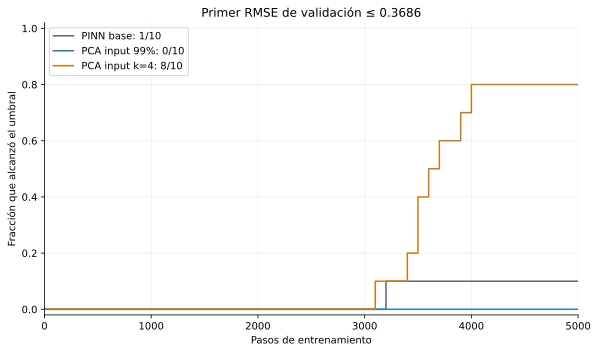

In [ ]:
display(SVG(filename=str(RUN_DIR / 'success_vs_steps.svg')))

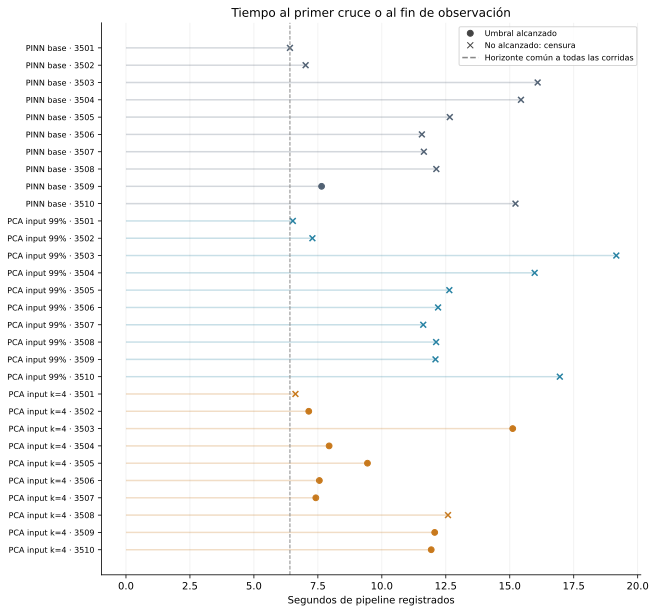

In [ ]:
display(SVG(filename=str(RUN_DIR / 'time_to_target_by_seed.svg')))

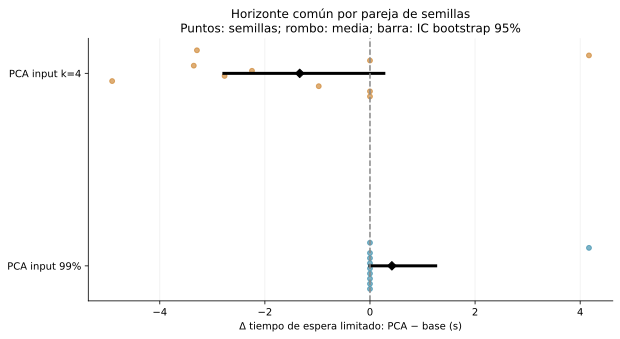

In [ ]:
display(SVG(filename=str(RUN_DIR / 'paired_common_horizon.svg')))

## Interpretación

Aciertos en 5000 pasos: PINN base: 1/10; PCA input 99%: 0/10; PCA input k=4: 8/10. Parejas que alcanzan el umbral en ambos modelos: PCA input k=4, semilla 3509: base 7.645 s, PCA 12.066 s.

Una mayor tasa de éxito dentro del presupuesto de pasos es evidencia de capacidad para alcanzar esta calidad, pero por sí sola no basta para concluir una aceleración general. El diagnóstico con horizontes por pareja aprovecha información de las corridas censuradas y debe leerse junto a su variación de presupuestos.

Una confirmación debe mantener este umbral fijo, usar semillas nuevas y medir un presupuesto de tiempo común definido antes de correr. Estos datos no contienen el residuo PDE en el instante del cruce; la conclusión de calidad equivalente se limita al RMSE de validación.

Regenerar: `python scripts/analyze_high_dim_time_to_target.py --config configs/high_dim_time_to_target.json`. Requiere Matplotlib, incluido en las dependencias opcionales de notebooks. Los CSV, el resumen y las figuras SVG/PNG se conservan en la carpeta de resultados del análisis.